## 01. Circular Convolution and The Cyclic Prefix

A wireless channel acts on a signal by **linear convolution**: the receiver
hears the transmitted signal plus delayed, scaled echoes of it. OFDM, the
modulation behind WiFi, 4G, and 5G, relies on a different operation,
**circular convolution**, because the DFT turns it into pointwise
multiplication:

$$Y[m] = H[m]\,X[m].$$

That identity lets a receiver undo the channel with one division per
frequency bin. This notebook works out how a short **cyclic prefix** makes the
channel's linear convolution look circular to the receiver, and what goes
wrong when the prefix is too short.

### Setup

We work with one block of $N = 64$ samples and a channel with $L = 5$ taps:
a direct path plus four echoes. Both are drawn at random, with a fixed seed
so the results reproduce.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

In [2]:
N = 64 # block length
L = 5 # number of channel taps

In [3]:
h = rng.standard_normal(L)   # channel taps: direct path plus L - 1 echoes
x = rng.standard_normal(N)   # one block of N samples

## Circular Convolution and The DFT

Let $W = e^{-2\pi i/N}$, so the $N$-point DFT is $X[m] = \sum_{n=0}^{N-1} x[n]\,W^{mn}$.
The channel $h$ has $L \le N$ taps, and we zero-pad it to length $N$, so both
sequences live on $\mathbb{Z}_N$.

**Definition.** The circular convolution of $h$ and $x$ is

$$y_c[n] = \sum_{k=0}^{N-1} h[k]\, x[(n-k) \bmod N], \qquad n = 0, \dots, N-1.$$

Since $h[k] = 0$ for $k \ge L$, only the first $L$ terms contribute.

**Theorem.** $Y_c[m] = H[m]\,X[m]$, where $H$ is the $N$-point DFT of the zero-padded $h$.

**Proof.**

$$
\begin{aligned}
Y_c[m] &= \sum_{n=0}^{N-1} \sum_{k=0}^{N-1} h[k]\, x[(n-k) \bmod N]\, W^{mn} \\
&= \sum_{k=0}^{N-1} h[k]\, W^{mk} \sum_{n=0}^{N-1} x[(n-k) \bmod N]\, W^{m(n-k)} \\
&= \sum_{k=0}^{N-1} h[k]\, W^{mk} \sum_{r=0}^{N-1} x[r]\, W^{mr} \\
&= H[m]\, X[m].
\end{aligned}
$$

The second line splits $W^{mn} = W^{mk}\,W^{m(n-k)}$. For the third, $W^N = 1$, so
$W^{m(n-k)}$ depends only on $(n-k) \bmod N$. For fixed $k$, as $n$ runs over
$0, \dots, N-1$, the index $r = (n-k) \bmod N$ runs over the same set exactly once. $\blacksquare$

**Remark.** $H$ must be the $N$-point DFT of the padded $h$, which is
`np.fft.fft(h, n=N)`. Without `n=N`, NumPy computes an $L$-point DFT, which
lives on $\mathbb{Z}_L$ instead.

In [4]:
def circular_convolve(h, x):
    """Circular convolution of h and x on Z_N, where N = len(x).
    h is zero-padded to length N. Output has length N.
    """
    h = np.asarray(h)
    x = np.asarray(x)
    N = len(x)
    L = len(h)
    if L > N:
        raise ValueError("h must not be longer than x")
    y = np.zeros(N, dtype=np.result_type(h, x))
    for n in range(N):
        for k in range(L):
            y[n] += h[k] * x[(n - k) % N]
    return y

We confirm the theorem numerically, up to floating-point rounding.

In [5]:
y = circular_convolve(h, x)
X = np.fft.fft(x)
H = np.fft.fft(h, n=N)
Y = np.fft.fft(y)
print(np.allclose(Y, H * X))
print(np.max(np.abs(Y - H * X)))

True
3.580361673049448e-15


### Linear vs Circular Convolution

The physical channel does not wrap around. It acts by **linear convolution**
on $\mathbb{Z}$,

$$y_{\text{lin}}[n] = \sum_{k=0}^{L-1} h[k]\, x[n-k],$$

where $x[n] = 0$ outside $0, \dots, N-1$. The output has length $N + L - 1$,
longer than the block, so the theorem above does not apply to it directly.
To relate the two, we sample the DTFT.

**Lemma (sampling the DTFT periodizes).** Let $y$ be finitely supported on
$\mathbb{Z}$ with DTFT $Y(\omega) = \sum_n y[n]\,e^{-i\omega n}$. Then the
inverse DFT of the samples $Y(2\pi m/N)$, $m = 0, \dots, N-1$, is the
periodization

$$\tilde y[r] = \sum_{j \in \mathbb{Z}} y[r + jN], \qquad r = 0, \dots, N-1.$$

**Proof.** Write each $n \in \mathbb{Z}$ uniquely as $n = r + jN$ with
$0 \le r < N$. Since $e^{-2\pi i m (r + jN)/N} = e^{-2\pi i m r/N}$,

$$Y\!\left(\tfrac{2\pi m}{N}\right) = \sum_{r=0}^{N-1} \Big(\sum_{j} y[r + jN]\Big) e^{-2\pi i m r/N},$$

which is the $N$-point DFT of $\tilde y$. The DFT is invertible. $\blacksquare$

This is discrete Poisson summation: sampling in frequency periodizes in time.

**Corollary (folding identity).** Apply the lemma to $y_{\text{lin}}$ and evaluate
the samples using the convolution theorems:

$$
\tilde y_{\text{lin}}
= \text{IDFT}_N\Big\{Y_{\text{lin}}\big(\tfrac{2\pi m}{N}\big)\Big\}
= \text{IDFT}_N\Big\{H\big(\tfrac{2\pi m}{N}\big)\,X\big(\tfrac{2\pi m}{N}\big)\Big\}
= \text{IDFT}_N\big\{H[m]\,X[m]\big\}
= y_c.
$$

The second equality is the DTFT convolution theorem on $\mathbb{Z}$. The third holds
because $h$ and $x$ are supported in $0, \dots, N-1$, so their DTFTs sampled at
$2\pi m/N$ are exactly their $N$-point DFTs. The last is the theorem above. Because
$y_{\text{lin}}$ has length $N + L - 1 < 2N$, at most two copies overlap:

$$y_c[n] = \begin{cases} y_{\text{lin}}[n] + y_{\text{lin}}[n + N], & 0 \le n \le L - 2, \\ y_{\text{lin}}[n], & L - 1 \le n \le N - 1. \end{cases}$$

Circular convolution is linear convolution with its tail folded onto its head.
The wraparound is time-domain aliasing caused by keeping only $N$ frequencies.

**Example.** Take $h = [1, 1]$ and $x = [1, 2, 3]$, so $N = 3$. With $z = e^{-i\omega}$,

$$Y_{\text{lin}}(\omega) = (1 + z)(1 + 2z + 3z^2) = 1 + 3z + 5z^2 + 3z^3.$$

Sampling at $\omega = 2\pi m/3$ forces $z^3 = 1$, so the last term lands on the first:
$4 + 3z + 5z^2$. Linear convolution gives $[1, 3, 5, 3]$, while circular convolution
gives $[4, 3, 5]$.

In [6]:
print(np.convolve([1, 1], [1, 2, 3]))          # linear:   [1 3 5 3]
print(circular_convolve([1, 1], [1, 2, 3]))    # circular: [4 3 5]

[1 3 5 3]
[4 3 5]


We check both claims on our block: the outputs differ only in the first
$L - 1$ samples, and folding the tail of $y_{\text{lin}}$ onto its head
recovers $y_c$ exactly.

In [7]:
y_lin = np.convolve(h, x)
print(len(y_lin))                                  # N + L - 1
print(np.flatnonzero(~np.isclose(y_lin[:N], y)))   # indices where they differ

68
[0 1 2 3]


In [8]:
folded = y_lin[:N].copy()
folded[:L-1] += y_lin[N:]
print(np.allclose(folded, y))

True


### The Cyclic Prefix

The channel performs linear convolution, but the receiver wants circular
convolution, because that is what the DFT diagonalizes. The cyclic prefix
bridges the gap: before transmitting, copy the last $P$ samples of the block
to its front.

It is convenient to index the prefixed block from $-P$:

$$x_{\text{cp}}[j] = x[j \bmod N], \qquad j = -P, \dots, N - 1.$$

The channel produces the linear convolution $r = h * x_{\text{cp}}$, and the
receiver discards the prefix, keeping $r[n]$ for $n = 0, \dots, N - 1$.

**Proposition.** If $P \ge L - 1$, then $r[n] = y_c[n]$ for $n = 0, \dots, N - 1$.

**Proof.** For $0 \le n \le N - 1$,

$$r[n] = \sum_{k=0}^{L-1} h[k]\, x_{\text{cp}}[n - k].$$

Every index satisfies $n - k \ge -(L - 1) \ge -P$, so it stays inside the
prefixed block, where $x_{\text{cp}}[n - k] = x[(n - k) \bmod N]$. Hence

$$r[n] = \sum_{k=0}^{L-1} h[k]\, x[(n - k) \bmod N] = y_c[n]. \qquad \blacksquare$$

In words, each output sample reaches back at most $L - 1$ samples, and a
prefix of length $P \ge L - 1$ places exactly the wrapped-around values there.
Linear convolution never knows it is computing something circular.

**Remark.** In a real system, blocks are sent back to back, and the echoes of
one block spill at most $L - 1$ samples into the next. With $P \ge L - 1$,
that spillover lands entirely in the prefix, which the receiver throws away.
The cost is that a fraction $P/(N + P)$ of transmit time carries no new data,
so real systems size the prefix to cover the longest expected echo and no more.
WiFi (802.11a/g), for example, uses $N = 64$ with a 16-sample prefix.

In [9]:
def add_cyclic_prefix(x, P):
    """Prepend the last P samples of x to x."""
    x = np.asarray(x)
    return np.concatenate([x[len(x) - P:], x])


def remove_cyclic_prefix(r, P, N):
    """Discard the first P samples of r and keep the next N."""
    return np.asarray(r)[P:P + N]

With $P = L - 1$, the received block matches the circular convolution exactly.
In code, discarding the prefix means starting at array index $P$, since Python
arrays start at index 0 rather than $-P$.

In [10]:
P = L - 1
x_cp = add_cyclic_prefix(x, P)
r = np.convolve(h, x_cp)               # what the channel does
y_rx = remove_cyclic_prefix(r, P, N)   # what the receiver keeps
print(np.allclose(y_rx, y))

True


### A prefix that is too short

When $P < L - 1$, the longest echoes reach past the start of the prefixed block.

**Proposition.** Let $0 \le P < L - 1$. Then $r[n] = y_c[n]$ for
$L - 1 - P \le n \le N - 1$, while for $0 \le n \le L - 2 - P$,

$$r[n] - y_c[n] = -\sum_{k=n+P+1}^{L-1} h[k]\, x[(n - k) \bmod N].$$

So only the first $L - 1 - P$ samples can be corrupted, and for generic $h$
and $x$ all of them are.

**Proof.** For $n \ge L - 1 - P$, every index satisfies
$n - k \ge n - (L - 1) \ge -P$, and the argument from the previous section
applies unchanged. For $n \le L - 2 - P$, the terms with $k \ge n + P + 1$
have $n - k < -P$. They reach before the start of the transmitted block,
where the linear convolution sees zeros. Those terms are missing from $r[n]$
but present in $y_c[n]$, which gives the formula. $\blacksquare$

The case $P = 0$ is no prefix at all. Then $r[n] = y_{\text{lin}}[n]$, and we
recover the $L - 1$ mismatched samples from the linear vs circular section.

**Remark.** In a real system, the missing terms are not zero. They are filled
by the tail of the previous block, so a short prefix lets one block leak into
the next. This is inter-symbol interference, and it is one of the main ways
OFDM degrades when the channel's echoes outlast the prefix.

In [11]:
for P in range(L - 1, -1, -1):
    y_rx = remove_cyclic_prefix(np.convolve(h, add_cyclic_prefix(x, P)), P, N)
    wrong = np.flatnonzero(~np.isclose(y_rx, y))
    print(f"P = {P}: wrong samples {wrong}, expected count {max(0, L - 1 - P)}")

P = 4: wrong samples [], expected count 0
P = 3: wrong samples [0], expected count 1
P = 2: wrong samples [0 1], expected count 2
P = 1: wrong samples [0 1 2], expected count 3
P = 0: wrong samples [0 1 2 3], expected count 4


The plot shows the error in the first few received samples for each prefix
length. Shortening the prefix by one sample corrupts one more sample at the
start of the block, and sample $0$, which reaches back the farthest, loses
the most terms.

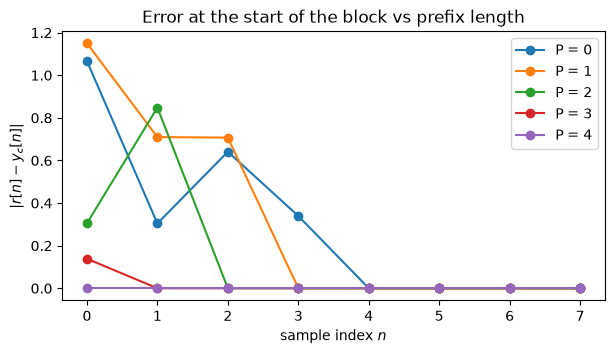

In [12]:
n_show = 8
fig, ax = plt.subplots(figsize=(7, 3.5))
for P in range(L):
    y_rx = remove_cyclic_prefix(np.convolve(h, add_cyclic_prefix(x, P)), P, N)
    ax.plot(np.arange(n_show), np.abs(y_rx - y)[:n_show], marker="o", label=f"P = {P}")
ax.set_xlabel("sample index $n$")
ax.set_ylabel(r"$|r[n] - y_c[n]|$")
ax.set_title("Error at the start of the block vs prefix length")
ax.legend()
plt.show()

## Summary

- The DFT diagonalizes **circular convolution** on $\mathbb{Z}_N$:
  $Y_c[m] = H[m]\,X[m]$.
- The channel performs **linear convolution** on $\mathbb{Z}$. Sampling its
  DTFT at $N$ frequencies periodizes it, so circular convolution is linear
  convolution with its tail folded onto its head.
- A **cyclic prefix** of length $P \ge L - 1$ makes the received block, after
  the prefix is discarded, equal to the circular convolution. The receiver can
  then undo the channel with one division per frequency bin.
- With $P < L - 1$, the first $L - 1 - P$ samples are corrupted, and in a real
  system the previous block leaks into the current one.

**Next:** put data on the $N$ frequency bins. Notebook 02 sends QPSK symbols
through noise and compares the bit error rate with theory.